# Week 7: Problem Framing, Neural Networks, and Cloud APIs

Last week we evaluated classical models (logistic regression, decision trees, random forests). This week: how to frame a problem for AI/ML, a first neural network, and how a cloud API changes the build-it-yourself equation.

**Roadmap:**

1. Problem framing: why images need a different approach
2. Intro to neural networks (demo and your turn)
3. Evaluating the network
4. Cloud APIs: train-it-yourself vs. call-a-service
5. In-class activity (IC-6): Cloud/NN build-vs-buy case

As before: a demo on a sample dataset, then Your Turn on your own dataset. Everyone uses the same dataset in Your Turn so we can compare results.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import io, zipfile, time, requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

pd.set_option('display.max_columns', 50)
pd.set_option('display.precision', 3)
print('Libraries loaded.')

Libraries loaded.


---
## Step 1 — Problem Framing: Why Images Need a Different Approach

Every model we've built so far took a table of columns (glucose level, BMI, age) and predicted a label. An image is also data, but each pixel is a feature. A small 28x28 pixel image has 784 features, and a single pixel by itself means almost nothing; what matters is the pattern of many pixels together.

Classical models like logistic regression or a decision tree can technically run on raw pixels, but they treat each pixel as an independent feature and miss how shapes form across neighboring pixels. That is the problem framing question for this week: when your features don't mean much individually, and only their combined pattern matters, that is a signal to reach for a neural network.

This is also a job-sizing question, not just a technical one: training your own model takes data, compute, and time. Later in the notebook we'll compare that against simply calling a cloud API that already has a trained model behind it.

---
## Step 2 — Intro to Neural Networks

A neural network is layers of simple units ("neurons") connected together. Each neuron takes a weighted sum of its inputs, passes it through a small nonlinear function (an "activation"), and sends the result to the next layer.

- **Input layer:** one unit per feature (one per pixel, for an image)
- **Hidden layer(s):** layers in between that combine features into higher-level patterns
- **Output layer:** one unit per class, giving a score for each possible digit

**Training** means adjusting every connection's weight so the network's output gets closer to the correct answer, repeated over many passes through the data (an algorithm called backpropagation, which we won't derive, just use).

**Demo dataset:** `load_digits`, a small built-in dataset of handwritten digit images (8x8 pixels, so 64 features, digits 0-9).

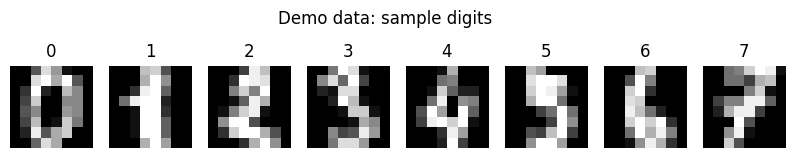

Shape: (1797, 64)  Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


In [2]:
from sklearn.datasets import load_digits

digits = load_digits()
X_demo = digits.data / 16.0     # pixel values range 0-16; scale to 0-1
y_demo = digits.target

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(int(y_demo[i]))
    ax.axis('off')
plt.suptitle('Demo data: sample digits')
plt.show()

print('Shape:', X_demo.shape, ' Classes:', sorted(set(y_demo)))

In [3]:
X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_demo, y_demo, test_size=0.2, random_state=42, stratify=y_demo
)

nn_demo = MLPClassifier(hidden_layer_sizes=(32,), max_iter=300, random_state=42)

t0 = time.time()
nn_demo.fit(X_train_d, y_train_d)
print(f'Trained in {time.time() - t0:.1f} seconds')
print('Network shape: 64 inputs ->', nn_demo.hidden_layer_sizes, '-> 10 outputs')

preds_demo = nn_demo.predict(X_test_d)
print('Test accuracy:', accuracy_score(y_test_d, preds_demo))

Trained in 1.9 seconds
Network shape: 64 inputs -> (32,) -> 10 outputs
Test accuracy: 0.9777777777777777


### Your Turn — Train a network on real MNIST

**Your dataset: MNIST**, the classic handwritten-digit dataset (28x28 pixels, so 784 features, 60,000 training images and 10,000 test images). We pull it from a public CSV mirror on GitHub, no sign-up needed.

Training on all 60,000 images takes under a minute, so we use the full set.

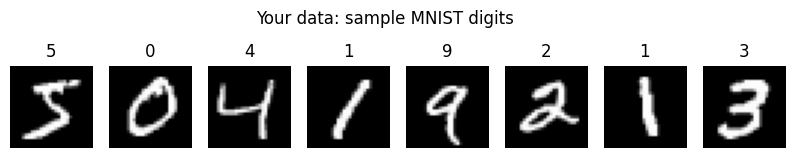

Train shape: (60000, 784)  Test shape: (10000, 784)


In [4]:
def load_mnist_csv(url):
    r = requests.get(url)
    z = zipfile.ZipFile(io.BytesIO(r.content))
    name = z.namelist()[0]
    return pd.read_csv(z.open(name), header=None)

base = 'https://raw.githubusercontent.com/phoebetronic/mnist/main/'
train_df = load_mnist_csv(base + 'mnist_train.csv.zip')
test_df = load_mnist_csv(base + 'mnist_test.csv.zip')

# First column is the label, remaining 784 columns are pixel values 0-255
y_train_y = train_df.iloc[:, 0].values
X_train_y = train_df.iloc[:, 1:].values / 255.0
y_test_y = test_df.iloc[:, 0].values
X_test_y = test_df.iloc[:, 1:].values / 255.0

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(X_train_y[i].reshape(28, 28), cmap='gray')
    ax.set_title(int(y_train_y[i]))
    ax.axis('off')
plt.suptitle('Your data: sample MNIST digits')
plt.show()

print('Train shape:', X_train_y.shape, ' Test shape:', X_test_y.shape)

In [5]:
nn_yours = MLPClassifier(hidden_layer_sizes=(100,), max_iter=20, random_state=42)

t0 = time.time()
nn_yours.fit(X_train_y, y_train_y)
print(f'Trained in {time.time() - t0:.1f} seconds')
print('Network shape: 784 inputs ->', nn_yours.hidden_layer_sizes, '-> 10 outputs')

preds_yours = nn_yours.predict(X_test_y)
print('Test accuracy:', accuracy_score(y_test_y, preds_yours))

Trained in 33.2 seconds
Network shape: 784 inputs -> (100,) -> 10 outputs
Test accuracy: 0.9759


**Your answers:**

1. How many total connections (weights) roughly exist between the input layer and your hidden layer alone? (Hint: inputs times hidden units.) What does that tell you about why training takes longer than our classical models from last week?
2. Compare your test accuracy here to the best classical model you got last week on a tabular dataset. Is image classification an easier or harder problem for a model, based on what you see?

---
## Step 3 — Evaluating the Network

Same tools as last week: confusion matrix, precision, recall, F1. With 10 classes instead of 2, the confusion matrix becomes a 10x10 grid, and precision/recall/F1 are usually averaged across classes.

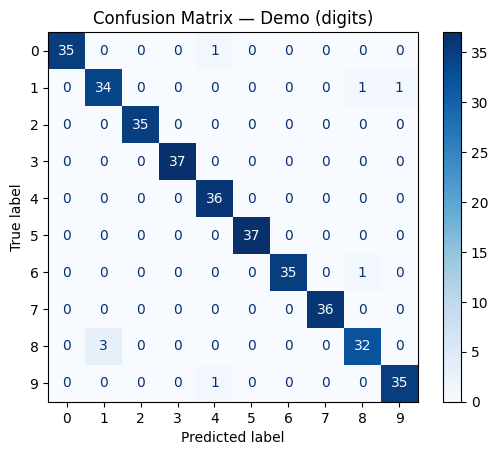

              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      0.94      0.93        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      1.00      0.97        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.94      0.91      0.93        35
           9       0.97      0.97      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [6]:
ConfusionMatrixDisplay.from_predictions(y_test_d, preds_demo, cmap='Blues')
plt.title('Confusion Matrix — Demo (digits)')
plt.show()

print(classification_report(y_test_d, preds_demo))

### Your Turn

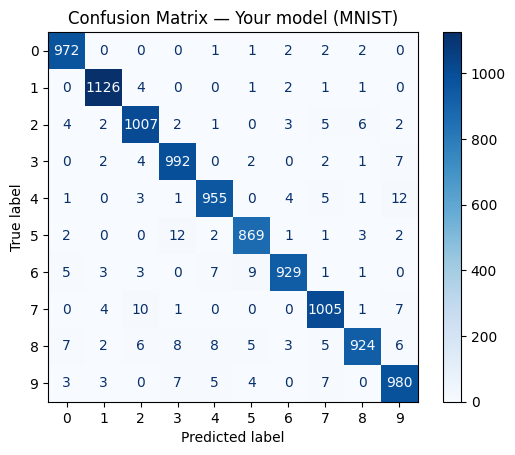

              precision    recall  f1-score   support

           0       0.98      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.97      1032
           3       0.97      0.98      0.98      1010
           4       0.98      0.97      0.97       982
           5       0.98      0.97      0.97       892
           6       0.98      0.97      0.98       958
           7       0.97      0.98      0.97      1028
           8       0.98      0.95      0.97       974
           9       0.96      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



In [7]:
ConfusionMatrixDisplay.from_predictions(y_test_y, preds_yours, cmap='Blues')
plt.title('Confusion Matrix — Your model (MNIST)')
plt.show()

print(classification_report(y_test_y, preds_yours))

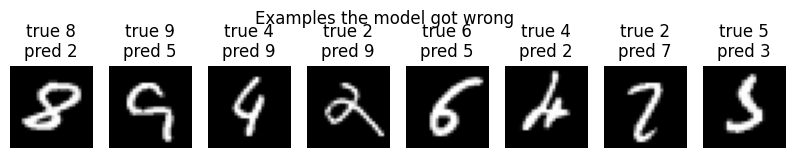

In [8]:
# Look at a few images the model got wrong
wrong = np.where(preds_yours != y_test_y)[0]
fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for i, ax in enumerate(axes[:len(wrong)]):
    idx = wrong[i]
    ax.imshow(X_test_y[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'true {y_test_y[idx]}\npred {preds_yours[idx]}')
    ax.axis('off')
plt.suptitle('Examples the model got wrong')
plt.show()

**Your answers:**

1. Which digit does your model confuse most often with another digit? Look at the confusion matrix off-diagonal values to find it. Why might those two digits be easy to confuse?
2. Look at the misclassified images. Do any of them look genuinely ambiguous even to you? What does that suggest about the ceiling on accuracy for this task?

---
## Step 4 — Cloud APIs: Train-It-Yourself vs. Call-a-Service

Training the network above took real time and a GPU-free laptop could handle it only because MNIST is small and well-behaved. Many real problems (translating language, recognizing arbitrary photos, generating text) need far more data and compute than a single class laptop can train from scratch.

A **cloud API** is a hosted model that already has those weights trained. Your code sends data over the internet to the provider's server and gets a prediction back, the same shape of interaction as any other web API. You pay per call instead of paying with your own training time and hardware.

| | Train your own | Call a cloud API |
|---|---|---|
| Upfront cost | Data collection, compute, your time | None, pay per call |
| Ongoing cost | You host and maintain it | Provider's usage fee, can scale with volume |
| Control | Full control over data and model | Limited to what the provider exposes |
| Data privacy | Data stays local | Data leaves your system |
| Latency | As fast as your own hardware | Network round-trip to the provider |
| Customization | Fully yours to adapt | Only what the API allows |

Below, we simulate calling a cloud API by wrapping our own trained network in a function with the same shape a real API call would have: send data in, get a prediction and confidence back. A real cloud vision API (Google Cloud Vision, AWS Rekognition, Azure AI Vision, etc.) works the same way, just with its own already-trained model and a request to its server instead of a function call.

In [9]:
def call_digit_api(image_vector, model=nn_demo):
    """Stand-in for a cloud API call: send an image, get a prediction and confidence back."""
    t0 = time.time()
    probs = model.predict_proba(image_vector.reshape(1, -1))[0]
    pred = int(np.argmax(probs))
    confidence = float(np.max(probs))
    latency_ms = (time.time() - t0) * 1000
    return {'prediction': pred, 'confidence': round(confidence, 3), 'latency_ms': round(latency_ms, 2)}

# Try it on one test image
sample = X_test_d[0]
result = call_digit_api(sample)
print('API-style response:', result)
print('Actual label:', y_test_d[0])

API-style response: {'prediction': 5, 'confidence': 0.984, 'latency_ms': 1.09}
Actual label: 5


**Your answers:**

1. If your clinic or company needed to classify a handful of images per day, would training your own network make sense? What if it needed to classify a million images per day? Explain the shift in reasoning.
2. Name one situation where sending data to a cloud API would be a bad idea regardless of cost, and explain why.

---
## Step 5 — In-Class Activity (IC-7): Build vs. Buy

### The case
A retailer wants to automatically read handwritten order forms and extract the quantity written in a box (a digit 0-9) at checkout. They're deciding between two paths:

- **Build:** train their own digit-recognition network like the one above, hosted on their own servers.
- **Buy:** call an existing cloud API that already does handwriting recognition.

They process about 50,000 forms a month today, expect to grow to 500,000 within a year, and the forms contain customer names and order details alongside the digits.

Discuss with your group, then write your answers.

1. Accuracy: our MNIST model above got into the high 90s on clean, centered digits. Real order forms will have messier handwriting. Does that change which option you'd lean toward, or does it affect both options equally?
2. Cost at scale: a typical cloud API charges roughly $1-1.50 per 1,000 images. Estimate the monthly cost at 50,000 forms and at 500,000 forms. At what point might hosting their own model become cheaper?
3. Data privacy: the forms contain customer names and order details. Does that change your recommendation?
4. Latency and reliability: does it matter whether predictions need to happen in real time at checkout versus overnight in a batch?
5. Your recommendation: build, buy, or a hybrid? Justify it with the numbers above.

**Your answers:**

**To submit for the in-class activity:** upload your written answers to the IC-6 module.

---
# Assignment 7 — Build, Evaluate, and Defend a Neural Network

Use the same MNIST data and trained network from above (run all earlier cells first). Write your own thoughts; answers that just restate numbers without explaining why won't get full credit.

---
## Task 1 — Try a different architecture

Train a second network with a different hidden layer setup and compare it to `nn_yours` from Step 2.

In [10]:
# TODO: change the hidden layer sizes. A tuple of (64, 32) means two hidden layers, 64 then 32 units.
nn_v2 = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=20, random_state=42)

t0 = time.time()
nn_v2.fit(X_train_y, y_train_y)
train_time = time.time() - t0

preds_v2 = nn_v2.predict(X_test_y)

comparison = pd.DataFrame({
    'Original (100,)': {
        'Accuracy': accuracy_score(y_test_y, preds_yours),
        'F1 (macro)': f1_score(y_test_y, preds_yours, average='macro'),
    },
    f'New {nn_v2.hidden_layer_sizes}': {
        'Accuracy': accuracy_score(y_test_y, preds_v2),
        'F1 (macro)': f1_score(y_test_y, preds_v2, average='macro'),
    },
}).T
comparison['Train time (s)'] = [None, round(train_time, 1)]
comparison

,Accuracy,F1 (macro),Train time (s)
"Original (100,)",0.976,0.976,NaN
"New (64, 32)",0.974,0.973,23.7


**Task 1 answer.** What architecture did you try, and did it beat the original? Did a bigger or more complex network clearly win, or were the gains small? What does that suggest about how much architecture matters once a network is already reasonably sized?

**Your answer:**

## Task 2 — Diagnose one failure pattern

Pick one digit your model struggles with most (from the Step 3 confusion matrix) and look closer at it.

51 test images of digit 9 were misclassified


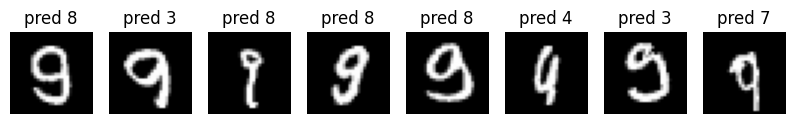

In [11]:
# TODO: set this to the digit your model confuses most often
digit_of_interest = 9

mask = (y_test_y == digit_of_interest) & (preds_v2 != digit_of_interest)
confused_idx = np.where(mask)[0]

print(f'{len(confused_idx)} test images of digit {digit_of_interest} were misclassified')
fig, axes = plt.subplots(1, min(8, len(confused_idx)), figsize=(10, 2))
for i, ax in enumerate(np.atleast_1d(axes)):
    idx = confused_idx[i]
    ax.imshow(X_test_y[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'pred {preds_v2[idx]}')
    ax.axis('off')
plt.show()

**Task 2 answer.** What digit did you pick, and what does the model most often mistake it for? Looking at the misclassified images, is there a visual reason (shape, slant, thickness) that explains the confusion?

**Your answer:**

## Task 3 — Build vs. buy, with your own numbers

Using the `call_digit_api` pattern from Step 4, estimate what it would cost to run your model's workload through a cloud API instead.

In [12]:
# TODO: fill in your own numbers for a scenario you choose (or reuse the IC-6 retailer case)
images_per_month = 200000       # TODO: edit
cloud_cost_per_1000 = 1.25      # TODO: edit, dollars per 1000 images

monthly_cloud_cost = images_per_month / 1000 * cloud_cost_per_1000
print(f'Estimated monthly cloud API cost: ${monthly_cloud_cost:,.2f}')

# Rough self-hosting comparison: training time scales roughly with data size
est_train_time_min = (train_time / 60) * (images_per_month / len(X_train_y))
print(f'Rough estimate of your own retraining time at this volume: {est_train_time_min:.1f} minutes')

Estimated monthly cloud API cost: $250.00
Rough estimate of your own retraining time at this volume: 1.3 minutes


**Task 3 answer.** What scenario and numbers did you use? Based on the cost estimate, would you build or buy, and why? What would have to change about the scenario (volume, accuracy needs, data sensitivity) to flip your recommendation?

**Your answer:**